## Module 2: FSHD Clinical Trial Project Template

Authors: Mona Abou-Assi and Victor Alvarado

## Project Goal:

The goal of this project is to determine which biomarkers and clinical outcome assessments are best at detecting FSHD progression. Using Python, we will analyze real patient data and provide evidence-based proposals for which biomarkers should be used in clinical trials for FSHD treatments. This project will explore the research question: **Which measure is more sensitive to change in FSHD patients, the clinical severity scores or the dorsi flexion?** The project will delve into how this research question pertains to the development and evaluation of treatments in a clinical-trial setting.

## Disease Background: 

**Prevalence & incidence:**
- FSHD is among the most prevalent muscular diseases (also known as myopathy). It is the most common hereditary muscular dystrophy. It affects men, women, and children. The prevalence of FSHD is approximately 1 in 7,500 people. However, the reality is that FSHD is underdiagnosed, and there may be more cases than recorded. Many people carry the gene without being symptomatic. This leads to the genetic prevalence being higher than the clinical prevalence. The incidence is estimated to be 1 in 14,286 births in the world. ("Facts and statistics FSHD", 2014)

**Symptoms**
- FSHD symptoms include weakness in the face, such as not being able to smile or pucker the lips, in the shoulders, making it difficult for patients to lift their arms, in the legs, causing difficulty in lifting the feet, and in the abdomen, leading to curves in the lower spine and affecting posture and balance. Another symptom is chronic pain and inflammation in the lower back, legs, neck, and shoulders. Less common symptoms include joint and spinal changes, respiratory problems, retinal changes, hearing loss, and difficulty swallowing. ("Diseases - FSHD - Signs & Symptoms", 2015) 

**Standard of care treatments (& reimbursement)**
- Medical management of FSHD is characterized by symptoms management, as there is no cure for the disease. Patients may be prescribed NSAIDs for pain management and antidepressant or antiepileptics for chronic pain. Rehabilitative devices are given to patients who need improved posture, including braces and postural supports. Some patients undergo a scapular fixation surgery, which stabilizes the shoulder blade and can lead to improved arm function. A low level of exercise is recommended to support the health and function of the patient. Most standard insurance companies will reimburse patients for their medications, physical therapy, and clinical visits. ("Muscular Dystrophy Association", 2015)

**Disease progression & prognosis**
- FSHD’s progression can begin from adolescence when symptoms may begin to show. However, FSHD’s progression over time for the most part is rather slow. As FSHD progresses symptoms arise primarily as muscle weakness in the face, lower girdle, upper arm, and lower leg. FSHD’s prognosis is that of a manageable disease that allows many affected individuals to live a relatively normal life with management strategies available such as support devices for weakened muscles or physical therapy. Nevertheless, it is estimated that around 20% of FSHD affected individuals end up wheelchairing bound. ("FSHD", 2023)

**Biological mechanisms (anatomy, organ physiology, cell & molecular physiology)**
- The expression of DUX4 is the leading molecular driver behind FSHD. Normally, DUX4 is repressed and remains off. There's two types of FSHD. FSHD type 1 is caused by chromatin relaxation in the D4Z4 repeat region on the 4th Chromosome. (Preston, 2025) The second type of FSHD is caused by epigenetic changes that affect SCHMD1, DNMT3B, and LRIFI genes which similarly lead to de-repression of DUX4. Once DUX4 is expressed in muscle tissue it leads to muscle fiber loss. The DUX4 expression alongside muscle MRIs can be used as biomarkers for FSHD. (Brun, 2026)

**Clinical Trials/next-gen therapies**
- Genetic therapies are being investigated with clinical trials to suppress DUX4. One approach uses siRNA to silence DUX4. The other approach uses epigenetic silencing of the D4Z4 repeat region on the 4th chromosome to reduce DUX4 expression. Lastly, a therapy focusing on using losmapimod found improvements in strengths alongside workspace reachability. However, the placebo group also had the same improvements. (Preston, 2025)

## Data Set:

Describe the FSHD dataset used in your project. Include:

- The subject and visit/timepoint(s) analyzed
- The tibialis anterior MRI data
- The water-image and fat-image files
- The tibialis anterior segmentation mask
- The sampled locations along the muscle
- The meaning and units of the image signals
- The clinical, biomarker, or functional measurements included in the dataset
- The source of the data

Explain how the MRI data and muscle mask were generated or provided for this project. Cite the paper, dataset documentation, or other sources that informed your description.

## MRI Data Analysis Methdology:

Describe the methods used to analyze the FSHD data. Include the Python code, tables, and figures needed for another researcher to reproduce your analysis.  Use the example from class to create this section.  NOte that you will not anaylze all the data that goes into the final project analysis.  Rather you are reproducing how one dataset was generated and using that to describe the methodology.

For the MRI analysis, explain:

- How the water, fat, and segmentation-mask files were loaded
- How the tibialis anterior mask was used to identify the muscle
- How fat fraction was calculated for the whole image region and for the TA muscle only
- How the fat-fraction distribution was summarized
- Which summary statistics were calculated, such as mean, median, standard deviation, and number of muscle pixels
- How measurements were summarized across locations along the muscle

If you compare visits or use interpolation in your final analysis, describe those methods clearly, including the variables used and the assumptions made.

Each figure should have labeled axes, an informative title, and a caption explaining what is shown, why it is included, and what conclusion can be drawn from it.

### Import Packages and Locate Data

Each library is imported for a different purpose in loading, processing, and visualizing our analysis. The pathlib locates the MRI dataset folder. The NumPy library is what handles MRI image calculations and arrays. The pandas library organizes information about the MRI slices into a table. The matplotlib.pyplot is what allows us to create the graphs and figures. The DATA_DIR call is what specifies the folder which contains the MRI data. The manifest code is what identifies the files and information for each MRI slice.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("FSHD_MRI_data/FSHD_TA_MRI_data_0020_TP1_TP2")
manifest = pd.read_csv(DATA_DIR / "slice_info.csv")
manifest

,subject,timepoint,slice_id,percent_along_muscle,z_index,distance_from_muscle_start_mm,water_file,fat_file,mask_file
0,UW_0020,TP1,1,10,41,24.0,TP1_slice_01_water.npy,TP1_slice_01_fat.npy,TP1_slice_01_mask.npy
1,UW_0020,TP1,2,20,46,44.0,TP1_slice_02_water.npy,TP1_slice_02_fat.npy,TP1_slice_02_mask.npy
2,UW_0020,TP1,3,30,52,68.0,TP1_slice_03_water.npy,TP1_slice_03_fat.npy,TP1_slice_03_mask.npy
3,UW_0020,TP1,4,40,58,92.0,TP1_slice_04_water.npy,TP1_slice_04_fat.npy,TP1_slice_04_mask.npy
4,UW_0020,TP1,5,50,64,116.0,TP1_slice_05_water.npy,TP1_slice_05_fat.npy,TP1_slice_05_mask.npy
5,UW_0020,TP1,6,60,69,136.0,TP1_slice_06_water.npy,TP1_slice_06_fat.npy,TP1_slice_06_mask.npy
6,UW_0020,TP1,7,70,75,160.0,TP1_slice_07_water.npy,TP1_slice_07_fat.npy,TP1_slice_07_mask.npy
7,UW_0020,TP1,8,80,81,184.0,TP1_slice_08_water.npy,TP1_slice_08_fat.npy,TP1_slice_08_mask.npy
8,UW_0020,TP2,1,10,40,24.0,TP2_slice_01_water.npy,TP2_slice_01_fat.npy,TP2_slice_01_mask.npy
9,UW_0020,TP2,2,20,46,48.0,TP2_slice_02_water.npy,TP2_slice_02_fat.npy,TP2_slice_02_mask.npy


### Load One Sample

One of the MRI slices from the first visit, TP1, is selected. In this case, it is in the fourth row (iloc[3]), which corresponds to 40% along the muscle. Three NumPy files get loaded, including the water image that contains MRI water-signal intensities, the fat image that shows fat-signal intensities, and the segmentation mask that shows the tibialis anterior muscle's image pixels. The code loads a segmentation-mask file that corresponds to the water and fat images on the same MRI slice. The code uses a boolean function: if it is true (1), the pixel belongs to the TA muscle, and if it is false (0), it do not belong to the TA muscle. This is important because the code takes out the pixels that include surrounding tissue, and it isolates the pixels with only the TA muscle. 

The output shows three different arrays based on the water image shape, fat image shape, and mask shape. All three arrays have the same dimensions of pixels in the array, so they can all be compared more easily. The third output is the number of pixels that belong to the tibialis anterior muscle. Overall, this data shows us that each image's dimensions are 226 x 224 pixels. The amount of pixels that have the tibialis muscle identified in them is 360 pixels. 


In [3]:
row = manifest[manifest["timepoint"] == "TP1"].iloc[3]  # representative mid-muscle slice

water = np.load(DATA_DIR / row["water_file"])
fat = np.load(DATA_DIR / row["fat_file"])
mask = np.load(DATA_DIR / row["mask_file"]).astype(bool)

print("Water image shape:", water.shape)
print("Fat image shape:", fat.shape)
print("Mask shape:", mask.shape)
print("Number of muscle pixels:", mask.sum())

Water image shape: (266, 224)
Fat image shape: (266, 224)
Mask shape: (266, 224)
Number of muscle pixels: 360


### Calculate Fat Fraction

The fat fraction is a measure of the proportion of fat in the combined water and fat signals from the MRI image. A higher percentage means there is more fat in the pixel. The formula for calculating fat fraction is: 

$$ \text{Fat Fraction} = \frac{\text{fat}}{\text{fat + water}}\cdot 100\%$$

The code divides the fat signals by the denominator, which is the water plus fat. The code ensures that the denominator is not equal to zero to avoid dividing by zero. The code creates a NumPy array for the full fat fraction, which is the TA muscle and the surrounding tissue for the first analysis. Another array created is the masked fat fraction, which is the fat fraction for only the regions with tibialis anterior muscle.  

The results show that the mean fat fraction for the whole supplied image region is 48.6%. The mean fat fraction for the muscle only is 29.9%. The TA muscle value is more relevant to this study because it focuses solely on the muscle being evaluated. 


In [4]:
denominator = water + fat
valid_pixels = denominator > 0

fat_fraction = np.divide(
    fat,
    denominator,
    out=np.zeros_like(fat, dtype=float),
    where=valid_pixels
) * 100

# Keep the whole supplied image region for the first analysis.
fat_fraction_full = fat_fraction.copy()

# Then apply the TA mask for the muscle-specific analysis.
fat_fraction_masked = fat_fraction.copy()
fat_fraction_masked[~mask] = np.nan

whole_image_values = fat_fraction_full[valid_pixels]
muscle_values = fat_fraction_masked[~np.isnan(fat_fraction_masked)]

print(f"Whole supplied image region — mean: {np.mean(whole_image_values):.1f}%")
print(f"Whole supplied image region — minimum: {np.min(whole_image_values):.1f}%")
print(f"Whole supplied image region — maximum: {np.max(whole_image_values):.1f}%")
print()
print(f"TA muscle only — mean: {np.mean(muscle_values):.1f}%")
print(f"TA muscle only — minimum: {np.min(muscle_values):.1f}%")
print(f"TA muscle only — maximum: {np.max(muscle_values):.1f}%")

Whole supplied image region — mean: 48.6%
Whole supplied image region — minimum: 0.0%
Whole supplied image region — maximum: 100.0%

TA muscle only — mean: 29.9%
TA muscle only — minimum: 0.5%
TA muscle only — maximum: 90.7%


### Visualize the Images, the Mask, and Fat-Fraction Map

The code generates four different images obtained from the same MRI slice. The first image combines the water and TA mask. The white highlighting shows the water signal and the red outline shows the TA muscle. The second image is the fat image and TA mask. The white highlighting shows the fat signal and the red outline shows the TA muscle. The third image shows the fat fraction in the whole image, including the TA muscle and its surrounding tissue. The fourth image shows the fat fraction solely in the TA muscle. The first two images are important because they allow us to visualize the fat and water content and locate the TA muscle in the MRI slice. The third and fourth images are important because it allows us to visualize the fat fraction in the whole slice and in solely the TA muscle. The fourth image is especially important because it is what we will perform the main analysis on. This image shows the fat fraction percentage and a corresponding color scheme to label each pixel.

The code does this by first creating the figure and then multiple panels where the MRI images appear. imshow() displays the MRI data arrays into an image. contour() is what allows the TA muscle to be outlined in red. Then, cmap tells Matplotlib to display certain colors based on the numerical values stored. cmap = "gray" is used for the water and fat images. The shades of gray represent MRI signal intensities. For the fat fraction color map, vmin and vmax are used to set the scale for fat fraction, and the colorbar corresponds with this scale. plt.show() is what shows the image. The arrap  

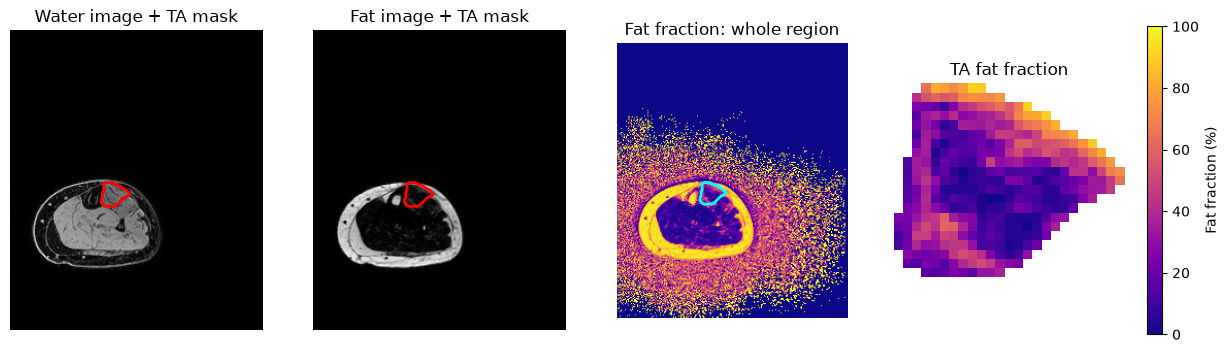

In [5]:
# Find the bounding box of the TA mask
y_pixels, x_pixels = np.where(mask)

y0, y1 = y_pixels.min(), y_pixels.max() + 1
x0, x1 = x_pixels.min(), x_pixels.max() + 1

# Crop the TA-specific fat-fraction map
fat_fraction_TA = fat_fraction_masked[y0:y1, x0:x1]

fig, axes = plt.subplots(1, 4, figsize=(15, 4))

# Water image with TA mask outline
axes[0].imshow(water, cmap="gray")
axes[0].contour(mask, levels=[0.5], colors="red", linewidths=2)
axes[0].set_title("Water image + TA mask")

# Fat image with TA mask outline
axes[1].imshow(fat, cmap="gray")
axes[1].contour(mask, levels=[0.5], colors="red", linewidths=2)
axes[1].set_title("Fat image + TA mask")

# Fat fraction for the whole supplied image region
whole_image = axes[2].imshow(
    fat_fraction_full,
    cmap="plasma",
    vmin=0,
    vmax=100
)
axes[2].contour(mask, levels=[0.5], colors="cyan", linewidths=2)
axes[2].set_title("Fat fraction: whole region")

# Zoomed-in fat fraction for the TA only
ta_image = axes[3].imshow(
    fat_fraction_TA,
    cmap="plasma",
    vmin=0,
    vmax=100
)
axes[3].set_title("TA fat fraction")

for ax in axes:
    ax.axis("off")

# Both fat-fraction plots use the same 0–100% scale
fig.colorbar(
    ta_image,
    ax=axes[2:],
    fraction=0.046,
    pad=0.04,
    label="Fat fraction (%)"
)

plt.show()

### Visualize the Fat-Fraction Distribution

This histograms displays the distribution of fat-fraction values in the whole supplied region and the TA muscle only, respectively.

This does this by retrieving whole_image_values, which contains the fat-fraction values from the whole image (calculated in the fat fraction section). The code plt.figure creates the figure and plt.hist specifically creates a histogram. The code bins=30 divides the data set into 30 different intervals, which makes up the x-axis of the graph (this is the same for both histograms). The bar heights represent the number of pixels that have that percentage of fat fraction on the graph. The rest of the code is the general formatting of the histogram. The same process is completed for the second histogram, but with the fat-fraction values for the TA muscle only. The TA-specific image is cropped by np.where(mask) finding the positions of the TA pixels in the whole MRI image. Array slicing is used to crop the image to only the TA muscle. Note the difference in values on the y-axis, as there are far less pixels being considered in the TA muscle only rather than the whole MRI image. 

This is important because it visualizes the data into an organized format where we can see the fat-fraction distribution for the whole supplied region and the TA muscle only. 

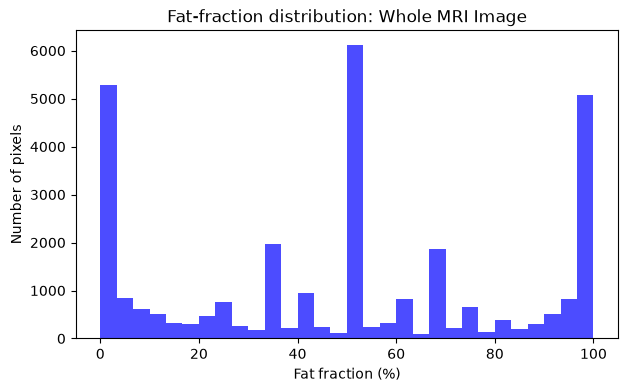

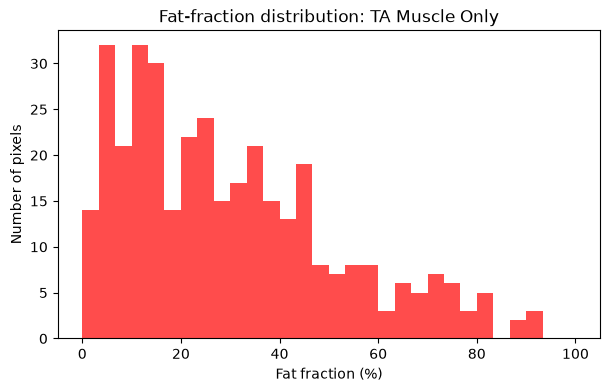

In [11]:
# Use the same bin boundaries for both datasets

# Use the same bins for both histograms
bins = np.linspace(0, 100, 31)

# Histogram 1: Whole MRI image
plt.figure(figsize=(7, 4))
plt.hist(whole_image_values, bins=bins, color="blue", alpha=0.7)
plt.xlabel("Fat fraction (%)")
plt.ylabel("Number of pixels")
plt.title("Fat-fraction distribution: Whole MRI Image")
plt.show()

# Histogram 2: TA muscle only
plt.figure(figsize=(7, 4))
plt.hist(muscle_values, bins=bins, color="red", alpha=0.7)
plt.xlabel("Fat fraction (%)")
plt.ylabel("Number of pixels")
plt.title("Fat-fraction distribution: TA Muscle Only")
plt.show()


### Repeat the Analysis for Every Sampled Location in One Visit

The function below packages the calculation so it can be reused for every row in the selected visit. This shows how the code generates the summary measurements. The def caculate_fat_fraction(water, fat, mask) defines a reusable Python function that inputs the water image, fat image, and segmentation mask, and returns an array that contains the fat-fraction percentages of the TA muscle pixels. The analysis_timepoint = "TP1" code picks a specific visit to be analyzed, TP1. Then an empty list is created for the results. A for loops is created that analyzes each MRI slice in TP1, and for each slice the water, fat, and mask files are loaded. The NumPy library is used to calculate the average fat-fraction percentage in TA muscle, middle fat-fraction percentage, and standard deviation. The code results.append() adds the measurements and information for each MRI slice in into the empty list. Then the list of measurements are converted into a DataFrame named results_df. Each row is one MRI location. 



In [ ]:
def calculate_fat_fraction(water, fat, mask): #Defines a reusable Python function.
    """Return a masked fat-fraction image in percent."""
    denominator = water + fat
    result = np.divide(
        fat,
        denominator,
        out=np.zeros_like(fat, dtype=float),
        where=denominator > 0
    ) * 100
    result[~mask] = np.nan
    return result

analysis_timepoint = "TP1"  # analyze one visit at a time
analysis_manifest = manifest[manifest["timepoint"] == analysis_timepoint]
results = []

for _, row in analysis_manifest.iterrows():
    water = np.load(DATA_DIR / row["water_file"])
    fat = np.load(DATA_DIR / row["fat_file"])
    mask = np.load(DATA_DIR / row["mask_file"]).astype(bool)
    ff = calculate_fat_fraction(water, fat, mask)

    results.append({
        "subject": row["subject"],
        "timepoint": row["timepoint"],
        "slice_id": row["slice_id"],
        "percent_along_muscle": row["percent_along_muscle"],
        "distance_from_muscle_start_mm": row["distance_from_muscle_start_mm"],
        "mean_fat_fraction_percent": np.nanmean(ff),
        "median_fat_fraction_percent": np.nanmedian(ff),
        "std_fat_fraction_percent": np.nanstd(ff),
        "n_muscle_pixels": int(mask.sum()),
    })

results_df = pd.DataFrame(results)
results_df

,subject,timepoint,slice_id,percent_along_muscle,distance_from_muscle_start_mm,mean_fat_fraction_percent,median_fat_fraction_percent,std_fat_fraction_percent,n_muscle_pixels
0,UW_0020,TP1,1,10,24.0,83.924382,88.827837,13.272006,61
1,UW_0020,TP1,2,20,44.0,82.706905,86.651582,12.433905,115
2,UW_0020,TP1,3,30,68.0,58.498513,61.821705,22.878862,231
3,UW_0020,TP1,4,40,92.0,29.931733,25.369646,21.584495,360
4,UW_0020,TP1,5,50,116.0,20.866866,14.553991,20.060150,421
5,UW_0020,TP1,6,60,136.0,16.758732,9.049959,19.665424,440
6,UW_0020,TP1,7,70,160.0,17.511838,8.962264,20.456168,388
7,UW_0020,TP1,8,80,184.0,27.873337,22.685185,22.625359,263


### Extension: Compare Fat Fraction Profiles Across Two Visits

This extension repeats the same calculation for TP1 and TP2. Use physical distance on the x-axis. The percent location is useful as a reference, but it is not a substitute for the measured spacing.

First, def summarize_visit creates a resuable function that takes one visit at a time and analyzes it. The input is the timepoint (i.e. TP1, TP2). Then, visit_manifest filters this data to sort out the slices from the specific visit. Each slice's fat fraction average is caluclated, adn the timepoint, slide ID, percentage along the muscle, and distance are recorded. Then, the visit's measurments are organized into a DataFrame. The TP1 and TP2 DataFrames are combined into a table, profiles_df. The TP1 and TP2 groups are separated with the groupby("timepoint") code. Then the measurement values are sorted by location along the muscle, which is helpful in creating the plotted points in the correct spatial order. plt.plot() plots the distance from start (mm) against the mean TA fat fraction (%). The rest of the code is the general formatting for the graph.

The output is a graph with two lines, one representing TP1 and the other representing TP2. The graph represents the mean TA fat fraction percentage at different distances from the muscle start. 

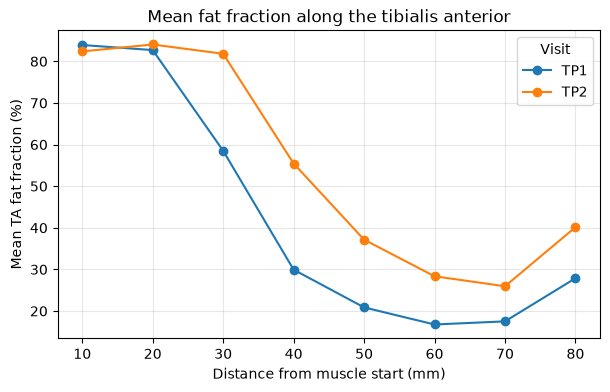

In [13]:
def summarize_visit(timepoint):
    visit_results = []
    visit_manifest = manifest[manifest["timepoint"] == timepoint]

    for _, row in visit_manifest.iterrows():
        water = np.load(DATA_DIR / row["water_file"])
        fat = np.load(DATA_DIR / row["fat_file"])
        mask = np.load(DATA_DIR / row["mask_file"]).astype(bool)
        ff = calculate_fat_fraction(water, fat, mask)

        visit_results.append({
            "timepoint": timepoint,
            "slice_id": row["slice_id"],
            "percent_along_muscle": row["percent_along_muscle"],
            "distance_from_muscle_start_mm": row["distance_from_muscle_start_mm"],
            "mean_fat_fraction_percent": np.nanmean(ff),
        })

    return pd.DataFrame(visit_results)

profiles_df = pd.concat(
    [summarize_visit("TP1"), summarize_visit("TP2")],
    ignore_index=True
)

plt.figure(figsize=(7, 4))
for timepoint, group in profiles_df.groupby("timepoint"):
    group = group.sort_values("distance_from_muscle_start_mm")
    plt.plot(
        group["percent_along_muscle"],
        group["mean_fat_fraction_percent"],
        marker="o",
        label=timepoint
    )
plt.xlabel("Distance from muscle start (mm)")
plt.ylabel("Mean TA fat fraction (%)")
plt.title("Mean fat fraction along the tibialis anterior")
plt.legend(title="Visit")
plt.grid(True, alpha=0.3)
plt.show()

### Save a Reusable Summary File

The calculated statistics are stored by first specifying the file location and name where the data is saved. The file is saved and exported in a csv file. The code prints a filename for the saved data.

It is important for the code to save this data because the results can be analyzed without having to rerun all this code. These measurements can also be imported into another coding platform and used. 

In [14]:
output_file = Path("TA_fat_fraction_summary.csv")
results_df.to_csv(output_file, index=False)
print(f"Saved {output_file}")

Saved TA_fat_fraction_summary.csv


### Longitudinal Comparison

If you run the analysis once for each visit, compare TP1 and TP2 at approximately the same percent location along the muscle. A change in MRI fat fraction may indicate a change in muscle composition, but it is not automatically evidence of improved or worsened patient function.

The code selects profiles_df if it exists, and if it does not exist results_df is used. The data is sorted so that TP1 and TP2 each have their own columns. Then, subtraction occurs between TP1 mean fat fraction and TP2 mean fat fraction. This difference is stored in "change_TP2_minus_TP1". The final table displays TP1, TP2 and the calculated difference for each location. The else statement prints a message that the users should run the two-visit extension if the required data is not available.

In [15]:
comparison_source = profiles_df if "profiles_df" in globals() else results_df
comparison = comparison_source.pivot(
    index="percent_along_muscle",
    columns="timepoint",
    values="mean_fat_fraction_percent"
)

if {"TP1", "TP2"}.issubset(comparison.columns):
    comparison["change_TP2_minus_TP1"] = comparison["TP2"] - comparison["TP1"]
    display(comparison)
else:
    print("Run the optional two-visit extension before making a longitudinal comparison.")

timepoint,TP1,TP2,change_TP2_minus_TP1
percent_along_muscle,,,
10,83.924382,82.390320,-1.534061
20,82.706905,84.049364,1.342458
30,58.498513,81.815108,23.316595
40,29.931733,55.449853,25.518120
50,20.866866,37.146636,16.279770
60,16.758732,28.351047,11.592316
70,17.511838,25.945668,8.433830
80,27.873337,40.143158,12.269821


## Interpolation Analysis:

Explain how interpolation was used to estimate fat fraction or another measurement at a location between sampled points along the tibialis anterior.

Include:

- The variable used to define location along the muscle, such as distance in millimeters or percentage of muscle length
- The sampled locations used as inputs to the interpolation
- The interpolation method and Python code used
- A plot showing the measured values and the interpolated estimate(s)
- Why interpolation is an estimate rather than a new measurement
- The assumptions made about how the measurement changes between sampled locations
- Whether the estimate is within the range of sampled data or represents extrapolation
- Any limitations or sources of uncertainty in the interpolated result

### Import Packages and Locate Data ###

Imports packages and locates the data

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d

### Linear Interpolation - the Math ###

Two known points `(x1, y1)` and `(x2, y2)`. We want the coefficients `a1` (intercept) and `a2` (slope) of `f(x) = a1 + a2*x`, by solving `Y = Z · A`.

This section provides the mathematical method of linear interpolation. Instead of using actual FSHD patient data, however, it uses sample numbers. 

The example plot demonstrates how to visualite interpolation as an example, not a final plot with actual FSHD results.

In [14]:
# Known points
x1, x2 = 1, 3
y1, y2 = 1, 3

# Z and Y matrices
Z = np.array([[1, x1],
              [1, x2]])
Y = np.array([y1, y2])

# Solve for A = [a1, a2]
A = np.linalg.solve(Z, Y)
print("A =", A)

A = [0. 1.]


In [16]:
# Use the coefficients to estimate y at a new x
a1, a2 = A
x_value = 2
y_value = a1 + a2 * x_value
print(f"At x = {x_value}, y = {y_value}")

At x = 2, y = 2.0


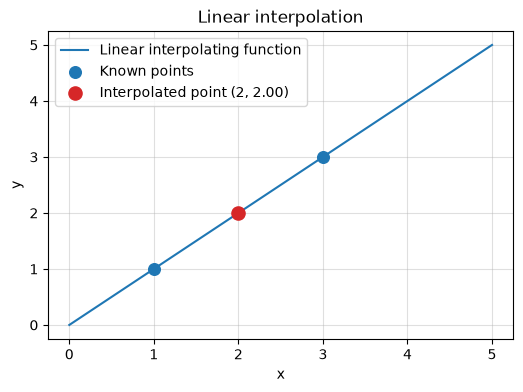

In [18]:
# Plot the line and the interpolated point
x_line = np.linspace(0, 5, 100)
y_line = a1 + a2 * x_line

plt.figure(figsize=(6, 4))
plt.plot(x_line, y_line, label="Linear interpolating function")
plt.scatter([x1, x2], [y1, y2], color="tab:blue", s=70, zorder=4, label="Known points")
plt.scatter([x_value], [y_value], color="tab:red", s=90, zorder=5,
            label=f"Interpolated point ({x_value}, {y_value:.2f})")
plt.title("Linear interpolation")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, alpha=0.4)
plt.legend()
plt.show()

### Quadratic Interpolation - the Math ###

Three known points. We want `a1, a2, a3` of `f(x) = a1 + a2*x + a3*x²`, again by solving `Y = Z · A` — this time `Z` has three columns: `[1, xi, xi²]`.

This section provides the mathematical method of quadratic interpolation. Instead of using actual FSHD patient data, however, it uses sample numbers. The example plot demonstrates how to visualite quadratic interpolation. 

In [20]:
# Known points
x1, x2, x3 = 1, 3, 5
y1, y2, y3 = 1, 3, 2

Z = np.array([[1, x1, x1**2],
              [1, x2, x2**2],
              [1, x3, x3**2]])
Y = np.array([y1, y2, y3])

A = np.linalg.solve(Z, Y)
print("A =", A)


A = [-1.125  2.5   -0.375]


In [21]:
a1, a2, a3 = A
x_value = 4
y_value = a1 + a2 * x_value + a3 * x_value**2
print(f"At x = {x_value}, y = {y_value}")


At x = 4, y = 2.875


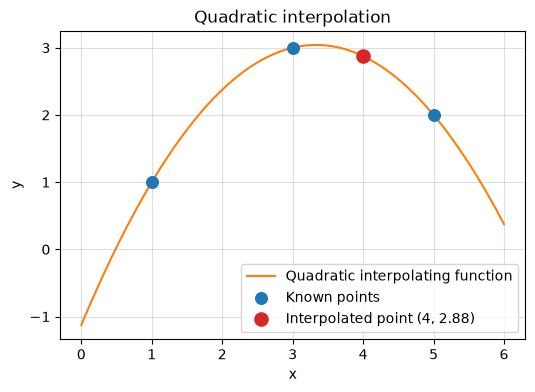

In [22]:
x_curve = np.linspace(0, 6, 200)
y_curve = a1 + a2 * x_curve + a3 * x_curve**2

plt.figure(figsize=(6, 4))
plt.plot(x_curve, y_curve, color="tab:orange", label="Quadratic interpolating function")
plt.scatter([x1, x2, x3], [y1, y2, y3], color="tab:blue", s=70, zorder=4, label="Known points")
plt.scatter([x_value], [y_value], color="tab:red", s=90, zorder=5,
            label=f"Interpolated point ({x_value}, {y_value:.2f})")
plt.title("Quadratic interpolation")
plt.xlabel("x")
plt.ylabel("y")
plt.grid(True, alpha=0.4)
plt.legend()
plt.show()

### Loading Our Data ###

`Module2_FSHD_Dataset.csv` has one row per subject, with separate columns for each visit (baseline, Year 1, Year 2) rather than one row per visit. Put the CSV in the same folder as this notebook.

The data uses the FSHD patient dataset to examine changes in clinical severity scores and dorsiflextion measurements over a unit of time. This dataset includes measurements from baseline, Year 1, and Year 2 visits, which allows us to analyze the disease progression and compare the sensitivity of the two clinical measurements.

In [23]:
df = pd.read_csv("/Users/monaabouassi/Desktop/FALL 26/BME 2315/BME 2315 Module 2/MODULE2/Untitled/Module2_FSHD_Dataset.csv")
print(df.shape)
df.head()

(34, 46)


,subject_id,sex,age_baseline,d4z4,dux4_signature_baseline_R,dux4_signature_baseline_L,lag_months_baseline,lag_months_y1,lag_months_y2,ff_baseline_R,...,wr_10_y2,ascend_4_baseline,ascend_4_y1,ascend_4_y2,descend_4_baseline,descend_4_y1,descend_4_y2,clinical_severity_score_baseline,clinical_severity_score_y1,clinical_severity_score_y2
0,1-0019,M,47.06,4,0.060426,0.052982,0,11.74,22.78,5.977253,...,2.52,1.89,2.13,1.63,1.76,1.84,1.64,2,3.0,3.0
1,1-0020,F,24.28,4,0.029324,0.085611,0,16.80,NaN,10.825636,...,NaN,2.15,2.50,NaN,1.89,2.07,NaN,4,6.0,NaN
2,1-0021,M,36.42,6,0.056946,0.264634,0,12.20,23.51,3.346368,...,2.65,1.40,1.60,1.76,1.52,1.40,1.39,0,0.0,1.0
3,1-0022,F,59.43,2,0.877067,0.217580,0,13.35,24.82,5.476659,...,4.44,1.97,2.15,1.97,1.87,2.25,2.27,3,3.0,2.0
4,1-0023,M,63.92,5,2.694204,2.876636,0,11.97,24.39,26.596680,...,3.59,2.32,2.26,2.20,2.00,2.13,2.15,4,4.0,6.0


In [24]:
# Check for missing visits -- not every subject has a Year 1 and/or Year 2 visit
print("Subjects:", len(df))
print("Have a Year 1 visit:", df['lag_months_y1'].notna().sum())
print("Have a Year 2 visit:", df['lag_months_y2'].notna().sum())

Subjects: 34
Have a Year 1 visit: 32
Have a Year 2 visit: 27


In [25]:
print(df.columns.tolist()) # prints the name of each column

['subject_id', 'sex', 'age_baseline', 'd4z4', 'dux4_signature_baseline_R', 'dux4_signature_baseline_L', 'lag_months_baseline', 'lag_months_y1', 'lag_months_y2', 'ff_baseline_R', 'ff_y1_R', 'ff_y2_R', 'ff_baseline_L', 'ff_y1_L', 'ff_y2_L', 'fvar_baseline_R', 'fvar_y1_R', 'fvar_y2_R', 'fvar_baseline_L', 'fvar_y1_L', 'fvar_y2_L', 'stir_quant_baseline_R', 'stir_quant_y1_R', 'stir_quant_baseline_L', 'stir_quant_y1_L', 'dorsiflexion_qmt_R_baseline', 'dorsiflexion_qmt_R_y1', 'dorsiflexion_qmt_R_y2', 'dorsiflexion_qmt_L_baseline', 'dorsiflexion_qmt_L_y1', 'dorsiflexion_qmt_L_y2', 'tug_time_baseline', 'tug_time_y1', 'tug_time_y2', 'wr_10_baseline', 'wr_10_y1', 'wr_10_y2', 'ascend_4_baseline', 'ascend_4_y1', 'ascend_4_y2', 'descend_4_baseline', 'descend_4_y1', 'descend_4_y2', 'clinical_severity_score_baseline', 'clinical_severity_score_y1', 'clinical_severity_score_y2']


## Conclusions:

Explain what your analysis suggests about measuring FSHD progression.

Discuss:

- Which MRI, biomarker, or functional measures changed most consistently
- Which measures appeared most sensitive to differences across muscle locations or visits
- Whether the measures could be useful as biomarkers or exploratory clinical-trial endpoints
- What additional evidence would be needed before using them to evaluate treatment effectiveness
- Potential ethical implications of selecting one measure over another, including patient relevance, accessibility, and the risk of overlooking meaningful changes in function

## Limitations and Future Work:

Describe the limitations of your project, including limitations of the sample size, available visits, MRI measurements, segmentation, biomarkers, functional measures, and analysis methods.

If you had more time or additional data, explain how you would improve the analysis. Examples include analyzing more participants, adding more timepoints, improving segmentation, comparing additional muscles, validating the MRI measure against functional outcomes, or testing whether the measure is sensitive to treatment response.

## AI Usage Statement:

We used ChatGPT to help write the code to split the histogram into two seperate histograms, one for the whole MRI image and one for solely the TA muscle. We used ChatGPT to reword some sentences to ensure grammar was correct. 

## GitHub Repository Link:

https://github.com/mabouassi2288/Module-2.git


## References:

<p style="text-indent: -1.5em; margin-left: 1.5em;">
    <b>Brun, B. N., Camarta, N., Johnson, N., Schoser, B., Statland, J., & Voermans, N. C. (2026). Overview of facioscapulohumeral dystrophy clinical features and diagnostic pathway. Neuromuscular Disorders, 61, 106389. https://doi.org/10.1016/j.nmd.2026.106389</b> 

 <p style="text-indent: -1.5em; margin-left: 1.5em;">
    <b>Diseases - FSHD - signs & symptoms. (2015, December 18). Muscular Dystrophy Association. https://www.mda.org/disease/facioscapulohumeral-muscular-dystrophy/signs-and-symptoms</b>    

 <p style="text-indent: -1.5em; margin-left: 1.5em;">
    <b>Facts and statistics FSHD - Wellstone Program - UMass Medical School - Worcester. (2014, March 4). University of Massachusetts Medical School. https://www.umassmed.edu/wellstone/overview/fshdfacts/</b>   

 <p style="text-indent: -1.5em; margin-left: 1.5em;">
    <b>FSHD (facioscapulohumeral muscular dystrophy). (2023, December 6). Cleveland Clinic. https://my.clevelandclinic.org/health/diseases/facioscapulohumeral-muscular-dystrophy-fshd</b>   

 <p style="text-indent: -1.5em; margin-left: 1.5em;">
    <b>Muscular Dystrophy Association. (2015, December 18). Facioscapulohumeral muscular dystrophy (FSH, FSHD) - medical management | muscular dystrophy association. Muscular Dystrophy Association. https://www.mda.org/disease/facioscapulohumeral-muscular-dystrophy/medical-management</b>   

 <p style="text-indent: -1.5em; margin-left: 1.5em;">
    <b>Preston, M. K., & Wang, L. H. (2025, July 10). Facioscapulohumeral muscular dystrophy. University of Washington, Seattle. Ncbibooks. https://www.ncbi.nlm.nih.gov/books/NBK1443/</b>   
   
 <p style="text-indent: -1.5em; margin-left: 1.5em;">
    <b>Wong, C. J., Friedman, S. D., Snider, L., Bennett, S. R., Jones, T. I., Jones, P. L., Shaw, D. W. W., Blemker, S. S., Riem, L., DuCharme, O., Lemmers, R. J. F. L., van der Maarel, S. M., Wang, L. H., Tawil, R., Statland, J. M., & Tapscott, S. J. (2024). Regional and bilateral MRI and gene signatures in facioscapulohumeral dystrophy: implications for clinical trial design and mechanisms of disease progression. Human molecular genetics, 33(8), 698–708. https://doi.org/10.1093/hmg/ddae007 /b>   

## NOTES FROM YOUR TEAM: 
*This is where our team is taking notes and recording activity.*

## QUESTIONS FOR YOUR TA: 
*These are questions we have for our TA.*